# Datensatz runterladen

In [ ]:
!pip install kagglehub

In [10]:
import kagglehub
import pandas

path = kagglehub.dataset_download("mchilamwar/predict-concrete-strength")
df = pandas.read_csv(f"{path}/ConcreteStrengthData.csv")
df = df.rename( columns={"CementComponent " : "CementComponent"} ) 
df

,CementComponent,BlastFurnaceSlag,FlyAshComponent,WaterComponent,SuperplasticizerComponent,CoarseAggregateComponent,FineAggregateComponent,AgeInDays,Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30
...,...,...,...,...,...,...,...,...,...
1025,276.4,116.0,90.3,179.6,8.9,870.1,768.3,28,44.28
1026,322.2,0.0,115.6,196.0,10.4,817.9,813.4,28,31.18
1027,148.5,139.4,108.6,192.7,6.1,892.4,780.0,28,23.70
1028,159.1,186.7,0.0,175.6,11.3,989.6,788.9,28,32.77


In [11]:
!dir $path

ConcreteStrengthData.csv


In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   CementComponent            1030 non-null   float64
 1   BlastFurnaceSlag           1030 non-null   float64
 2   FlyAshComponent            1030 non-null   float64
 3   WaterComponent             1030 non-null   float64
 4   SuperplasticizerComponent  1030 non-null   float64
 5   CoarseAggregateComponent   1030 non-null   float64
 6   FineAggregateComponent     1030 non-null   float64
 7   AgeInDays                  1030 non-null   int64  
 8   Strength                   1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.6 KB


In [13]:
df.columns

Index(['CementComponent', 'BlastFurnaceSlag', 'FlyAshComponent',
       'WaterComponent', 'SuperplasticizerComponent',
       'CoarseAggregateComponent', 'FineAggregateComponent', 'AgeInDays',
       'Strength'],
      dtype='str')

# Wie schwer ist das Problem eigentlich?

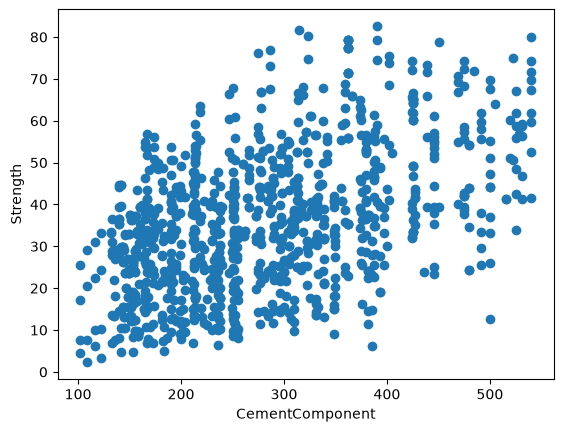

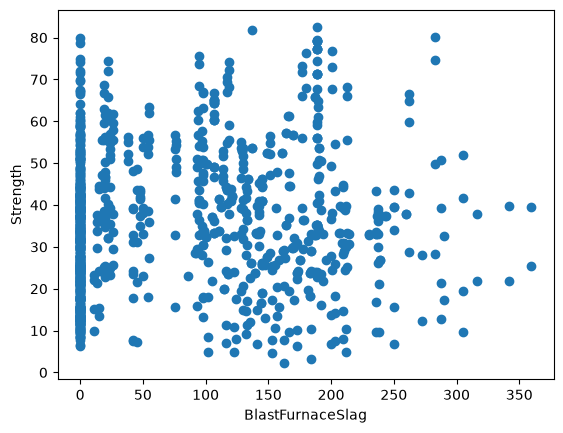

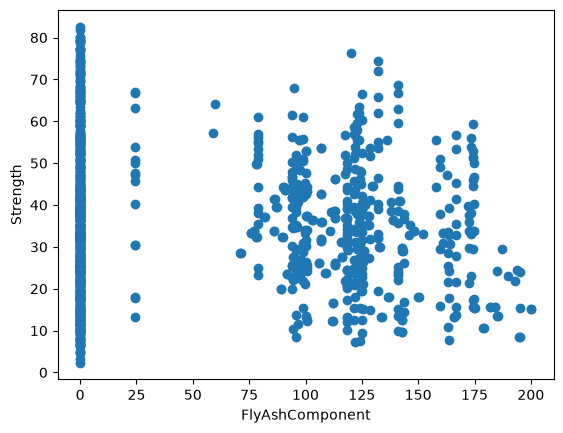

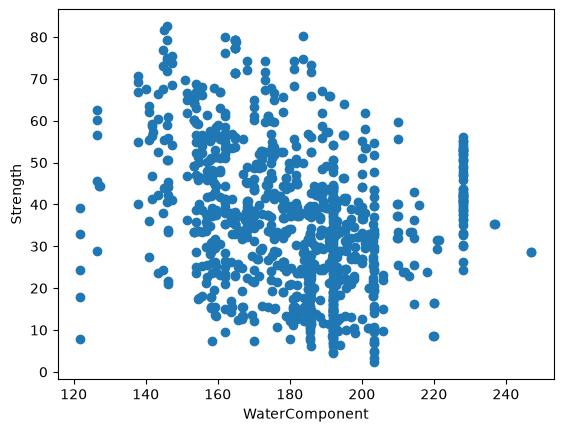

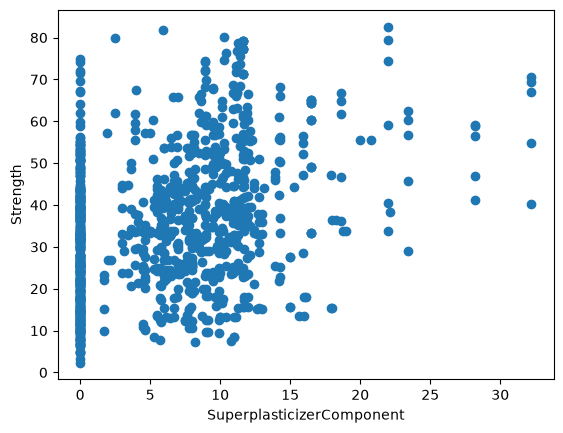

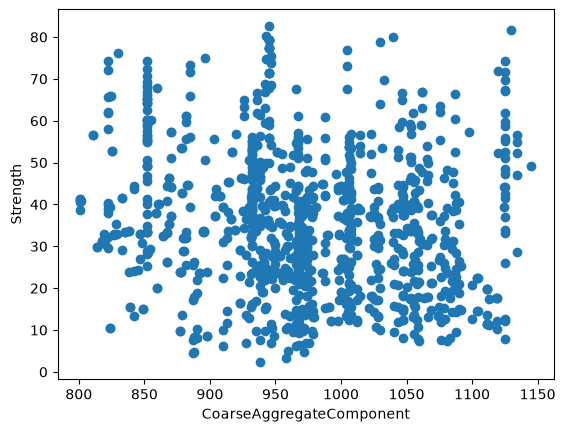

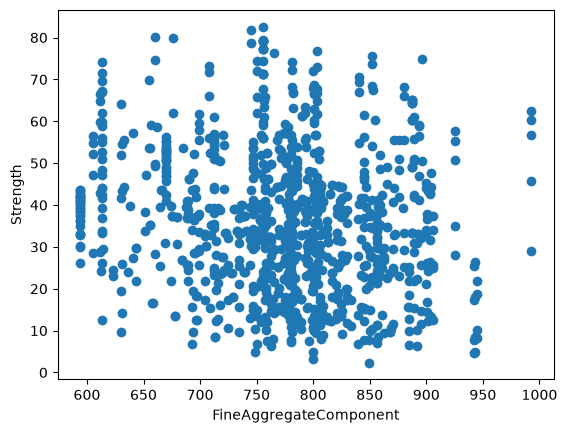

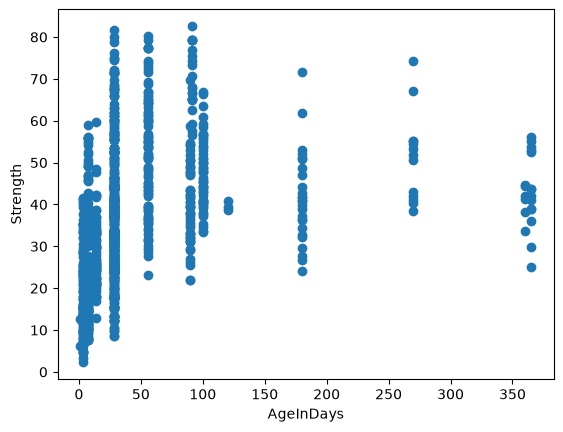

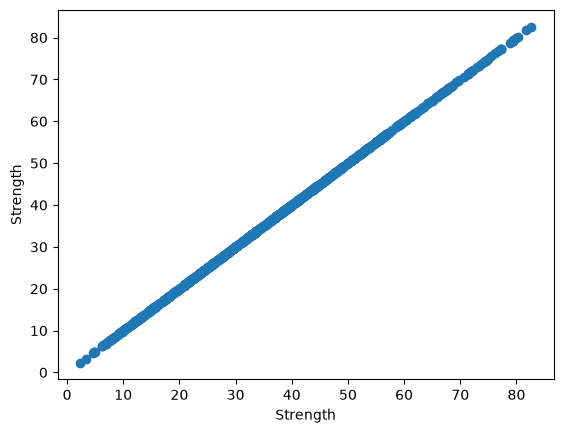

In [18]:
import matplotlib.pyplot as plt
for x in df.columns:
    y = "Strength"
    plt.scatter( df[x], df[y] )
    plt.xlabel(x)
    plt.ylabel(y)
    plt.show()

In [17]:
df.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
CementComponent,1030.0,281.167864,104.506364,102.00,192.375,272.900,350.000,540.0
BlastFurnaceSlag,1030.0,73.895825,86.279342,0.00,0.000,22.000,142.950,359.4
FlyAshComponent,1030.0,54.188350,63.997004,0.00,0.000,0.000,118.300,200.1
WaterComponent,1030.0,181.567282,21.354219,121.80,164.900,185.000,192.000,247.0
SuperplasticizerComponent,1030.0,6.204660,5.973841,0.00,0.000,6.400,10.200,32.2
CoarseAggregateComponent,1030.0,972.918932,77.753954,801.00,932.000,968.000,1029.400,1145.0
FineAggregateComponent,1030.0,773.580485,80.175980,594.00,730.950,779.500,824.000,992.6
AgeInDays,1030.0,45.662136,63.169912,1.00,7.000,28.000,56.000,365.0
Strength,1030.0,35.817961,16.705742,2.33,23.710,34.445,46.135,82.6


| Englische Bezeichnung     | Deutsche Übersetzung                  |
| ------------------------- | ------------------------------------- |
| CementComponent           | Zementanteil                          |
| BlastFurnaceSlag          | Hochofenschlacke                      |
| FlyAshComponent           | Flugascheanteil                       |
| WaterComponent            | Wasseranteil                          |
| SuperplasticizerComponent | Fließmittelanteil (Betonverflüssiger) |
| CoarseAggregateComponent  | Grobe Gesteinskörnung (Kies)          |
| FineAggregateComponent    | Feine Gesteinskörnung (Sand)          |
| AgeInDays                 | Alter in Tagen                        |
| Strength                  | Druckfestigkeit                       |

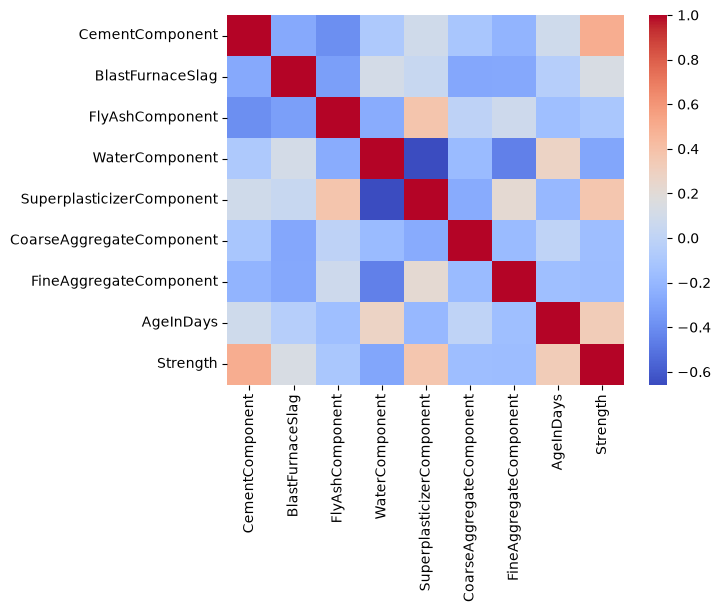

In [21]:
import seaborn as sns
sns.heatmap( df.corr(), cmap="coolwarm" )
plt.show()

# Daten fürs ML vorbereiten

In [23]:
zielspalte = "Strength"
x = df.drop( zielspalte, axis="columns" )
y = df[ [zielspalte] ]
y

,Strength
0,79.99
1,61.89
2,40.27
3,41.05
4,44.30
...,...
1025,44.28
1026,31.18
1027,23.70
1028,32.77


In [24]:
x.shape

(1030, 8)

In [25]:
y.shape

(1030, 1)

In [26]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x,y, test_size=0.2, random_state=42)

In [31]:
x_train.shape

(824, 8)

In [32]:
y_train.shape

(824, 1)

In [33]:
x_test.shape

(206, 8)

In [34]:
y_test.shape

(206, 1)

In [36]:
x_train.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
CementComponent,824.0,283.360801,107.536404,102.0,192.000,275.10,359.900,540.0
BlastFurnaceSlag,824.0,74.371602,86.977784,0.0,0.000,22.00,144.775,359.4
FlyAshComponent,824.0,53.160801,64.000646,0.0,0.000,0.00,118.300,195.0
WaterComponent,824.0,181.797087,21.321905,121.8,164.900,185.35,192.000,247.0
SuperplasticizerComponent,824.0,6.163956,5.967258,0.0,0.000,6.10,10.125,32.2
CoarseAggregateComponent,824.0,973.548544,78.694630,801.0,932.000,968.00,1040.600,1145.0
FineAggregateComponent,824.0,772.107403,80.984717,594.0,726.775,778.50,821.250,992.6
AgeInDays,824.0,44.661408,60.475702,1.0,12.250,28.00,56.000,365.0


In [37]:
d = {"A" : [10,-10,0,5,-5],
     "B" : [20000,10000,-20000,0,-10000]}
df_test = pandas.DataFrame(d)
df_test

,A,B
0,10,20000
1,-10,10000
2,0,-20000
3,5,0
4,-5,-10000


In [42]:
from sklearn.preprocessing import MinMaxScaler
s = MinMaxScaler()
s.set_output(transform="pandas")
s.fit(df_test)
s.transform(df_test)

,A,B
0,1.00,1.00
1,0.00,0.75
2,0.50,0.00
3,0.75,0.50
4,0.25,0.25


In [43]:
from sklearn.preprocessing import MinMaxScaler
s_input = MinMaxScaler()
s_output = MinMaxScaler()
s_input.set_output(transform="pandas")
s_output.set_output(transform="pandas")
x_train_scaled = s_input.fit_transform(x_train)
y_train_scaled = s_output.fit_transform(y_train)

In [44]:
x_train_scaled

,CementComponent,BlastFurnaceSlag,FlyAshComponent,WaterComponent,SuperplasticizerComponent,CoarseAggregateComponent,FineAggregateComponent,AgeInDays
995,0.129224,0.414302,0.594872,0.425719,0.465839,0.442733,0.315354,0.074176
507,0.735160,0.061213,0.676923,0.448882,0.263975,0.061047,0.391370,0.074176
334,0.395205,0.000000,0.622564,0.301118,0.307453,0.734302,0.460361,0.005495
848,0.342466,0.269894,0.389744,0.576677,0.248447,0.098837,0.569493,0.074176
294,0.152740,0.117418,0.637436,0.291534,0.335404,0.813372,0.507275,0.005495
...,...,...,...,...,...,...,...,...
87,0.420776,0.558987,0.000000,0.182907,0.347826,0.591860,0.526091,0.005495
330,0.330594,0.000000,0.641538,0.171725,0.372671,0.830814,0.519067,0.035714
466,0.201598,0.000000,0.642051,0.357827,0.307453,0.808140,0.514049,0.271978
121,0.851598,0.330551,0.000000,0.473642,0.276398,0.148547,0.470396,0.074176


In [45]:
y_train_scaled

,Strength
995,0.315809
507,0.743989
334,0.267472
848,0.387069
294,0.063162
...,...
87,0.274947
330,0.496948
466,0.389062
121,0.821851


In [48]:
x_train_scaled.values

array([[0.12922374, 0.41430161, 0.59487179, ..., 0.44273256, 0.31535374,
        0.07417582],
       [0.73515982, 0.06121313, 0.67692308, ..., 0.06104651, 0.39136979,
        0.07417582],
       [0.39520548, 0.        , 0.6225641 , ..., 0.73430233, 0.46036126,
        0.00549451],
       ...,
       [0.20159817, 0.        , 0.64205128, ..., 0.80813953, 0.51404917,
        0.27197802],
       [0.85159817, 0.33055092, 0.        , ..., 0.14854651, 0.47039639,
        0.07417582],
       [0.48401826, 0.        , 0.57948718, ..., 0.36046512, 0.47415956,
        0.07417582]], shape=(824, 8))

In [65]:
import torch

x_train_scaled_tensor = torch.tensor(x_train_scaled.values, dtype=torch.float32)
y_train_scaled_tensor = torch.tensor(y_train_scaled.values, dtype=torch.float32)

# MLP mit PyTorch bauen

In [57]:
y_train.shape

(824, 1)

In [59]:
params = {"nr_inputs"  : x_train.shape[1],
          "nr_outputs" : y_train.shape[1],
          "nr_neurons_layer1" : 10}

In [60]:
from torch import nn

model = nn.Sequential(
            nn.Linear(params["nr_inputs"], params["nr_neurons_layer1"]),
            nn.ReLU(),
            nn.Linear(params["nr_neurons_layer1"], params["nr_outputs"])
)

In [61]:
type(model)

torch.nn.modules.container.Sequential

In [62]:
model

Sequential(
  (0): Linear(in_features=8, out_features=10, bias=True)
  (1): ReLU()
  (2): Linear(in_features=10, out_features=1, bias=True)
)

In [66]:
loss_function = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(1):
    # Feedforward
    predictions = model( x_train_scaled_tensor )

In [67]:
x_train_scaled_tensor

tensor([[0.1292, 0.4143, 0.5949,  ..., 0.4427, 0.3154, 0.0742],
        [0.7352, 0.0612, 0.6769,  ..., 0.0610, 0.3914, 0.0742],
        [0.3952, 0.0000, 0.6226,  ..., 0.7343, 0.4604, 0.0055],
        ...,
        [0.2016, 0.0000, 0.6421,  ..., 0.8081, 0.5140, 0.2720],
        [0.8516, 0.3306, 0.0000,  ..., 0.1485, 0.4704, 0.0742],
        [0.4840, 0.0000, 0.5795,  ..., 0.3605, 0.4742, 0.0742]])

In [68]:
predictions.shape

torch.Size([824, 1])

In [69]:
y_train.shape

(824, 1)

In [70]:
predictions[:5]

tensor([[-0.3151],
        [-0.3639],
        [-0.3651],
        [-0.3447],
        [-0.3621]], grad_fn=<SliceBackward0>)